In [ ]:
# 1. Clone the repository
!git clone https://github.com/TheDatumOrg/TSB-AD
# STEP 2: Navigate into the cloned folder path (/content/TSB-AD)
%cd TSB-AD
# STEP 3: Install all required Python packages from the requirements text file
!pip install -r requirements.txt --verbose

In [ ]:
%cd TSB-AD
# STEP 4: Install the TSB-AD package in editable mode from the current directory
!pip install -e .
# STEP 5: Download the full zip file from the external URL address
!wget https://www.thedatum.org/datasets/TSB-AD-U.zip
!wget https://www.thedatum.org/datasets/TSB-AD-M.zip

In [5]:
# 1. Unzip and automatically overwrite existing files (-o forces "yes")
!unzip -oq TSB-AD-U.zip -d Datasets/
!unzip -oq TSB-AD-M.zip -d Datasets/
# 2. Delete the zip files to free up disk space in Colab
!rm TSB-AD-U.zip TSB-AD-M.zip

replace Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace Datasets/TSB-AD-M/057_SMD_id_1_Facility_tr_4529_1st_4629.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y


In [6]:
!python -m TSB_AD.main --AD_Name IForest

CUDA Available:  False
cuDNN Version:  None
/content/TSB-AD/TSB_AD/evaluation/affiliation/_integral_interval.py:128: SyntaxWarning: invalid escape sequence '\i'
  integral of distance from x to J over the interval x \in I.
/content/TSB-AD/TSB_AD/evaluation/affiliation/_integral_interval.py:147: SyntaxWarning: invalid escape sequence '\i'
  integral of distance from x to J over the interval x \in I.
/content/TSB-AD/TSB_AD/evaluation/affiliation/_integral_interval.py:181: SyntaxWarning: invalid escape sequence '\i'
  compute the integral $\int_{d_min}^{d_max} \min(m, x) dx$, with:
/content/TSB-AD/TSB_AD/evaluation/affiliation/_integral_interval.py:217: SyntaxWarning: invalid escape sequence '\i'
  compute the integral $\int_{x \in I} Fbar(dist(x,J)) dx$.
/content/TSB-AD/TSB_AD/evaluation/affiliation/_integral_interval.py:247: SyntaxWarning: invalid escape sequence '\i'
  Compute the integral $\int_{x \in I} Fbar(dist(x,J)) dx$.
/content/TSB-AD/TSB_AD/evaluation/affiliation/_integral_inte

Running Isolation Forest via TSB-AD framework wrapper...


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



--- AUTOMATIC EVALUATION METRICS TABLE ---
        Metric  Score                                                                         Definition      Ideal Trend
         PA-F1 0.8543         Point-Adjusted F1-score (forgives errors if a single anomaly point is hit) Higher is better
 Affiliation-F 0.8233              Precision/Recall score based on proximity intervals to true anomalies Higher is better
       VUS-ROC 0.7529           Volume Under the Surface for ROC (range-based structural spatial metric) Higher is better
       AUC-ROC 0.6811 Area Under Receiver Operating Characteristic Curve (overall separation capability) Higher is better
Event-based-F1 0.3701                       F1 score calculated based on catching whole anomaly segments Higher is better
   Standard-F1 0.2641                        Strict point-by-point harmonic mean of Precision and Recall Higher is better
    R-based-F1 0.1970   Range-based F1 score adjusting for overlap and fragmentation positional criter

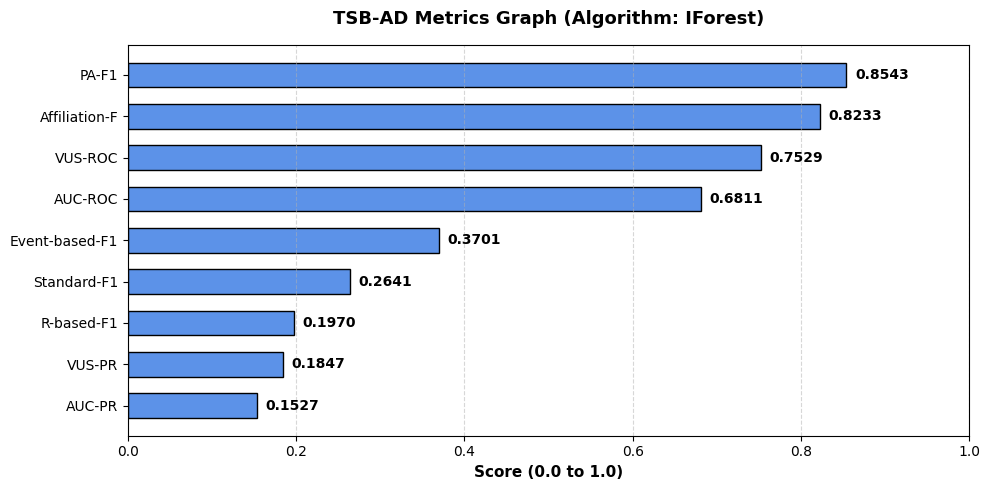

In [10]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Correct official imports from TSB-AD wrappers
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

# Dictionary to map metric names to descriptions and ideal target trends
METRIC_INFO = {
    'AUC-PR': ('Area Under Precision-Recall Curve (captures precision on imbalanced data)', 'Higher is better'),
    'AUC-ROC': ('Area Under Receiver Operating Characteristic Curve (overall separation capability)', 'Higher is better'),
    'VUS-PR': ('Volume Under the Surface for Precision-Recall (TSB-AD framework core range metric)', 'Higher is better'),
    'VUS-ROC': ('Volume Under the Surface for ROC (range-based structural spatial metric)', 'Higher is better'),
    'Standard-F1': ('Strict point-by-point harmonic mean of Precision and Recall', 'Higher is better'),
    'PA-F1': ('Point-Adjusted F1-score (forgives errors if a single anomaly point is hit)', 'Higher is better'),
    'Event-based-F1': ('F1 score calculated based on catching whole anomaly segments', 'Higher is better'),
    'R-based-F1': ('Range-based F1 score adjusting for overlap and fragmentation positional criteria', 'Higher is better'),
    'Affiliation-F': ('Precision/Recall score based on proximity intervals to true anomalies', 'Higher is better')
}

# 2. Define data path
data_path = 'Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv'

if not os.path.exists(data_path):
    print(f"Error: Could not find the dataset at {data_path}")
    print("Please make sure your unzip command placed the files in the 'Datasets/' folder.")
else:
    # 3. Load the data using pandas
    df = pd.read_csv(data_path).dropna()

    # Extract continuous feature matrix and ground truth binary array
    data_features = df.iloc[:, 0:-1].values.astype(float)
    y_true = df['Label'].astype(int).to_numpy()

    # 4. Initialize framework anomaly detector execution wrapper
    print("Running Isolation Forest via TSB-AD framework wrapper...")
    AD_Name = 'IForest'
    y_score = run_Unsupervise_AD(AD_Name, data_features)

    # 5. Automatically calculate all benchmark metrics
    metrics_dict = get_metrics(y_score, y_true)

    # 6. Convert the metrics dictionary into a formatted pandas table with explanations
    table_data = []
    for metric_name, score_val in metrics_dict.items():
        desc, trend = METRIC_INFO.get(metric_name, ('Custom framework metric', 'Higher is better'))
        table_data.append({
            'Metric': metric_name,
            'Score': round(score_val, 4),
            'Definition': desc,
            'Ideal Trend': trend
        })

    df_metrics = pd.DataFrame(table_data).sort_values(by='Score', ascending=False)

    print("\n--- AUTOMATIC EVALUATION METRICS TABLE ---")
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 1000)
    print(df_metrics.to_string(index=False))
    print("\n" + "="*40 + "\n")

    # 7. Generate and display the horizontal bar graph
    plt.figure(figsize=(10, 5))
    bars = plt.barh(df_metrics['Metric'], df_metrics['Score'], color='#5c92e8', edgecolor='black', height=0.6)

    # Styling and adjustments
    plt.xlim(0, 1.0)
    plt.gca().invert_yaxis()  # Places the highest score at the top
    plt.xlabel('Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
    plt.title(f'TSB-AD Metrics Graph (Algorithm: {AD_Name})', fontsize=13, fontweight='bold', pad=15)
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    # Add numeric labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
                 va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()


Running Principal Component Analysis (PCA) via TSB-AD framework wrapper...


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



--- AUTOMATIC EVALUATION METRICS TABLE ---
        Metric  Score                                                                         What it is      Ideal Trend
         PA-F1 1.0000         Point-Adjusted F1-score (forgives errors if a single anomaly point is hit) Higher is better
Event-based-F1 1.0000                       F1 score calculated based on catching whole anomaly segments Higher is better
 Affiliation-F 0.9963              Precision/Recall score based on proximity intervals to true anomalies Higher is better
       VUS-ROC 0.9357           Volume Under the Surface for ROC (range-based structural spatial metric) Higher is better
       AUC-ROC 0.9059 Area Under Receiver Operating Characteristic Curve (overall separation capability) Higher is better
   Standard-F1 0.8285                        Strict point-by-point harmonic mean of Precision and Recall Higher is better
        VUS-PR 0.8136 Volume Under the Surface for Precision-Recall (TSB-AD framework core range metri

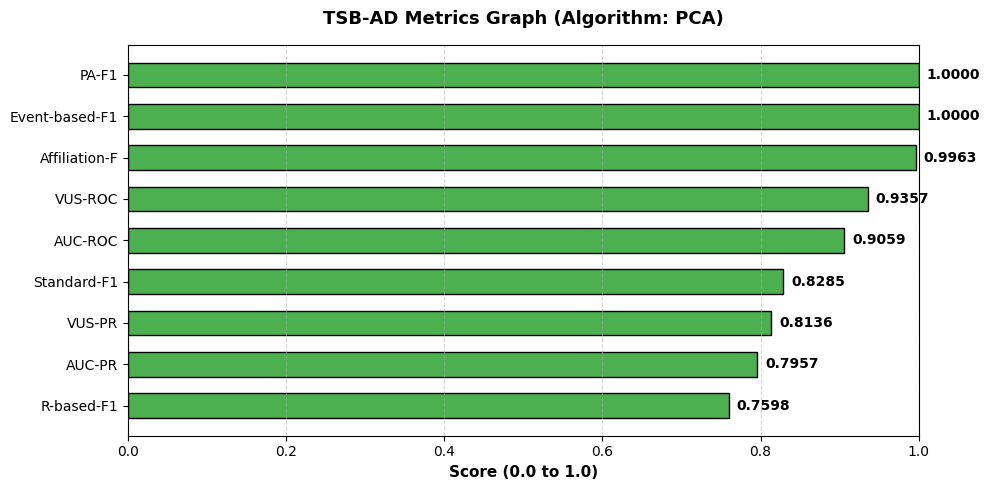

In [11]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Correct official imports from TSB-AD wrappers
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

# Dictionary to map metric names to descriptions and ideal target trends
METRIC_INFO = {
    'AUC-PR': ('Area Under Precision-Recall Curve (captures precision on imbalanced data)', 'Higher is better'),
    'AUC-ROC': ('Area Under Receiver Operating Characteristic Curve (overall separation capability)', 'Higher is better'),
    'VUS-PR': ('Volume Under the Surface for Precision-Recall (TSB-AD framework core range metric)', 'Higher is better'),
    'VUS-ROC': ('Volume Under the Surface for ROC (range-based structural spatial metric)', 'Higher is better'),
    'Standard-F1': ('Strict point-by-point harmonic mean of Precision and Recall', 'Higher is better'),
    'PA-F1': ('Point-Adjusted F1-score (forgives errors if a single anomaly point is hit)', 'Higher is better'),
    'Event-based-F1': ('F1 score calculated based on catching whole anomaly segments', 'Higher is better'),
    'R-based-F1': ('Range-based F1 score adjusting for overlap and fragmentation positional criteria', 'Higher is better'),
    'Affiliation-F': ('Precision/Recall score based on proximity intervals to true anomalies', 'Higher is better')
}

# 2. Define data path
data_path = 'Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv'

if not os.path.exists(data_path):
    print(f"Error: Could not find the dataset at {data_path}")
    print("Please make sure your unzip command placed the files in the 'Datasets/' folder.")
else:
    # 3. Load the data using pandas
    df = pd.read_csv(data_path).dropna()

    # Extract continuous feature matrix and ground truth binary array
    data_features = df.iloc[:, 0:-1].values.astype(float)
    y_true = df['Label'].astype(int).to_numpy()

    # 4. Initialize framework anomaly detector execution wrapper
    # CHANGED TO 'PCA'
    print("Running Principal Component Analysis (PCA) via TSB-AD framework wrapper...")
    AD_Name = 'PCA'
    y_score = run_Unsupervise_AD(AD_Name, data_features)

    # 5. Automatically calculate all benchmark metrics
    metrics_dict = get_metrics(y_score, y_true)

    # 6. Convert the metrics dictionary into a formatted pandas table with explanations
    table_data = []
    for metric_name, score_val in metrics_dict.items():
        desc, trend = METRIC_INFO.get(metric_name, ('Custom framework metric', 'Higher is better'))
        table_data.append({
            'Metric': metric_name,
            'Score': round(score_val, 4),
            'What it is': desc,
            'Ideal Trend': trend
        })

    df_metrics = pd.DataFrame(table_data).sort_values(by='Score', ascending=False)

    print("\n--- AUTOMATIC EVALUATION METRICS TABLE ---")
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 1000)
    print(df_metrics.to_string(index=False))
    print("\n" + "="*40 + "\n")

    # 7. Generate and display the horizontal bar graph
    plt.figure(figsize=(10, 5))
    bars = plt.barh(df_metrics['Metric'], df_metrics['Score'], color='#4caf50', edgecolor='black', height=0.6)

    # Styling and adjustments
    plt.xlim(0, 1.0)
    plt.gca().invert_yaxis()  # Places the highest score at the top
    plt.xlabel('Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
    plt.title(f'TSB-AD Metrics Graph (Algorithm: {AD_Name})', fontsize=13, fontweight='bold', pad=15)
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    # Add numeric labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
                 va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()


Running Robust PCA (RobustPCA) via TSB-AD framework wrapper...
iteration: 1, error: 177.46382471450235
iteration: 100, error: 0.015389713056124374
iteration: 200, error: 0.005992057360999846
iteration: 300, error: 0.003315082570030327
iteration: 400, error: 0.0021882249216519218
iteration: 500, error: 0.0015711510220960607
iteration: 600, error: 0.0012541105889681762
iteration: 700, error: 0.001029674705805917
iteration: 800, error: 0.0008521308083146247
iteration: 900, error: 0.0006883244000001447
iteration: 1000, error: 0.0005667409569134587


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p


--- AUTOMATIC EVALUATION METRICS TABLE ---
        Metric  Score                                                                         What it is      Ideal Trend
       VUS-ROC 0.5073           Volume Under the Surface for ROC (range-based structural spatial metric) Higher is better
       AUC-ROC 0.5000 Area Under Receiver Operating Characteristic Curve (overall separation capability) Higher is better
   Standard-F1 0.1568                        Strict point-by-point harmonic mean of Precision and Recall Higher is better
        VUS-PR 0.1114 Volume Under the Surface for Precision-Recall (TSB-AD framework core range metric) Higher is better
        AUC-PR 0.0851          Area Under Precision-Recall Curve (captures precision on imbalanced data) Higher is better
         PA-F1 0.0000         Point-Adjusted F1-score (forgives errors if a single anomaly point is hit) Higher is better
Event-based-F1 0.0000                       F1 score calculated based on catching whole anomaly segmen

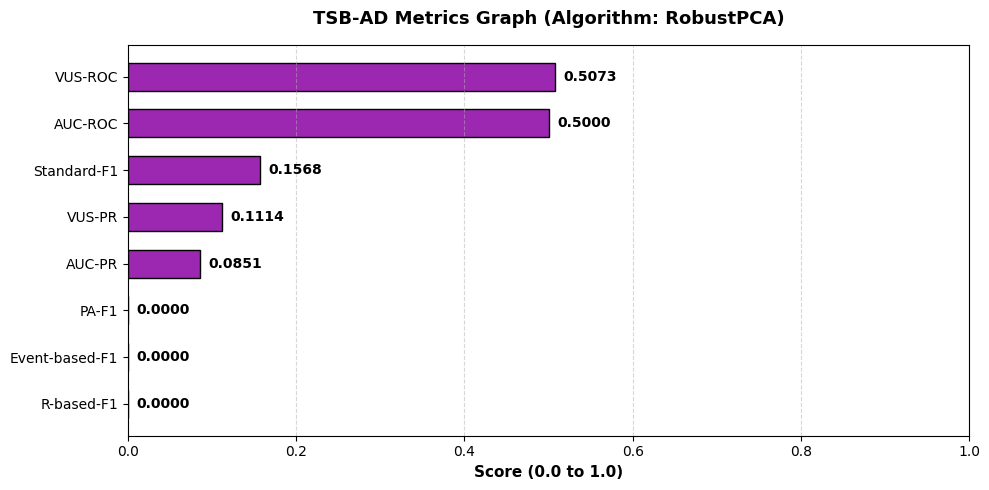

In [12]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Correct official imports from TSB-AD wrappers
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

# Dictionary to map metric names to descriptions and ideal target trends
METRIC_INFO = {
    'AUC-PR': ('Area Under Precision-Recall Curve (captures precision on imbalanced data)', 'Higher is better'),
    'AUC-ROC': ('Area Under Receiver Operating Characteristic Curve (overall separation capability)', 'Higher is better'),
    'VUS-PR': ('Volume Under the Surface for Precision-Recall (TSB-AD framework core range metric)', 'Higher is better'),
    'VUS-ROC': ('Volume Under the Surface for ROC (range-based structural spatial metric)', 'Higher is better'),
    'Standard-F1': ('Strict point-by-point harmonic mean of Precision and Recall', 'Higher is better'),
    'PA-F1': ('Point-Adjusted F1-score (forgives errors if a single anomaly point is hit)', 'Higher is better'),
    'Event-based-F1': ('F1 score calculated based on catching whole anomaly segments', 'Higher is better'),
    'R-based-F1': ('Range-based F1 score adjusting for overlap and fragmentation positional criteria', 'Higher is better'),
    'Affiliation-F': ('Precision/Recall score based on proximity intervals to true anomalies', 'Higher is better')
}

# 2. Define data path
data_path = 'Datasets/TSB-AD-U/001_NAB_id_1_Facility_tr_1007_1st_2014.csv'

if not os.path.exists(data_path):
    print(f"Error: Could not find the dataset at {data_path}")
    print("Please make sure your unzip command placed the files in the 'Datasets/' folder.")
else:
    # 3. Load the data using pandas
    df = pd.read_csv(data_path).dropna()

    # Extract continuous feature matrix and ground truth binary array
    data_features = df.iloc[:, 0:-1].values.astype(float)
    y_true = df['Label'].astype(int).to_numpy()

    # 4. Initialize framework anomaly detector execution wrapper
    # CHANGED TO 'RobustPCA'
    print("Running Robust PCA (RobustPCA) via TSB-AD framework wrapper...")
    AD_Name = 'RobustPCA'
    y_score = run_Unsupervise_AD(AD_Name, data_features)

    # 5. Automatically calculate all benchmark metrics
    metrics_dict = get_metrics(y_score, y_true)

    # 6. Convert the metrics dictionary into a formatted pandas table with explanations
    table_data = []
    for metric_name, score_val in metrics_dict.items():
        desc, trend = METRIC_INFO.get(metric_name, ('Custom framework metric', 'Higher is better'))
        table_data.append({
            'Metric': metric_name,
            'Score': round(score_val, 4),
            'What it is': desc,
            'Ideal Trend': trend
        })

    df_metrics = pd.DataFrame(table_data).sort_values(by='Score', ascending=False)

    print("\n--- AUTOMATIC EVALUATION METRICS TABLE ---")
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 1000)
    print(df_metrics.to_string(index=False))
    print("\n" + "="*40 + "\n")

    # 7. Generate and display the horizontal bar graph
    plt.figure(figsize=(10, 5))
    bars = plt.barh(df_metrics['Metric'], df_metrics['Score'], color='#9c27b0', edgecolor='black', height=0.6)

    # Styling and adjustments
    plt.xlim(0, 1.0)
    plt.gca().invert_yaxis()  # Places the highest score at the top
    plt.xlabel('Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
    plt.title(f'TSB-AD Metrics Graph (Algorithm: {AD_Name})', fontsize=13, fontweight='bold', pad=15)
    plt.grid(axis='x', linestyle='--', alpha=0.5)

    # Add numeric labels to the end of each bar
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.4f}',
                 va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()


Using Multivariate Dataset File: Datasets/TSB-AD-M/001_Genesis_id_1_Sensor_tr_4055_1st_15538.csv

Data shape loaded: 16220 rows, 18 sensor columns.

1/2: Running Standard PCA...


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


2/2: Running Robust PCA...
iteration: 1, error: 61384.5132679457
iteration: 100, error: 211.65771874753688
iteration: 200, error: 174.48031461402164
iteration: 300, error: 166.38970437539146
iteration: 400, error: 155.34098629240856
iteration: 500, error: 162.3641784768468
iteration: 600, error: 130.9147991206077
iteration: 700, error: 56.55845302150144
iteration: 800, error: 45.17551464852501
iteration: 900, error: 38.89034931516909
iteration: 1000, error: 33.824119465080024


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



 MULTIVARIATE ALGORITHM COMPARISON TABLE 
 Metric Target  Standard PCA Score  Robust PCA Score
        AUC-PR              0.0216            0.0023
       AUC-ROC              0.9271            0.3629
 Affiliation-F              0.8666            0.6695
Event-based-F1              0.0660            0.0061
         PA-F1              0.0981            0.0067
    R-based-F1              0.0924            0.0021
   Standard-F1              0.0667            0.0073
        VUS-PR              0.0947            0.0045
       VUS-ROC              0.9530            0.4355



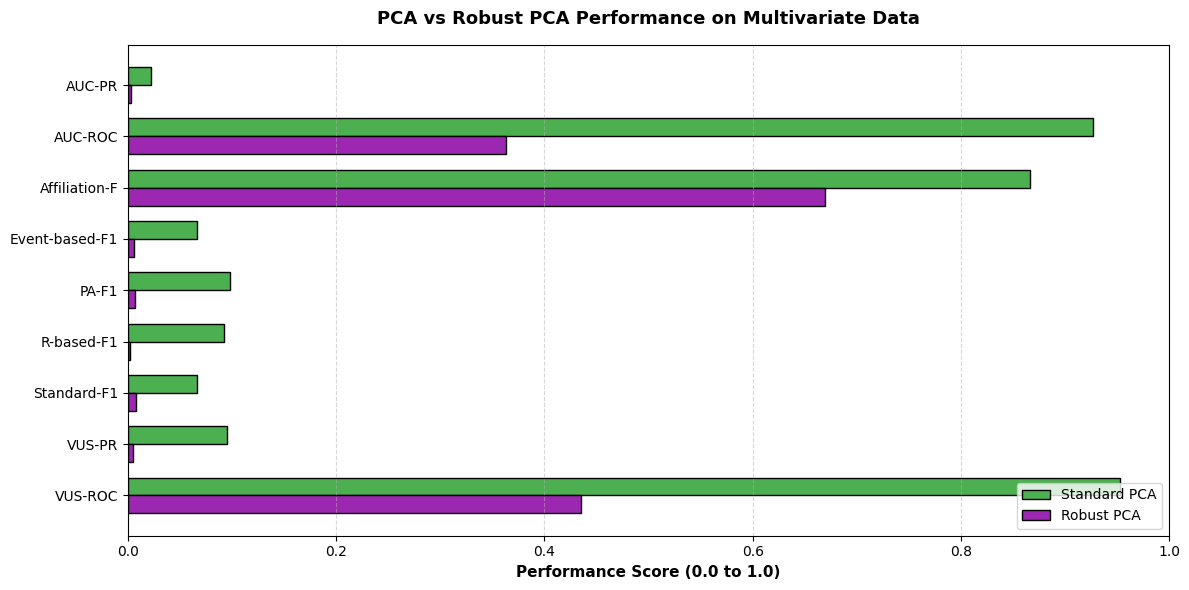

In [13]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Framework wrapper imports
from TSB_AD.model_wrapper import run_Unsupervise_AD
from TSB_AD.evaluation.metrics import get_metrics

# 2. Define your Multivariate file path
# Note: If your file has a slightly different name (like the tr_4529 one from your earlier logs),
# update this filename string to match an exact CSV inside your Datasets/TSB-AD-M/ folder.
data_path = 'Datasets/TSB-AD-M/001_SMD_id_1.csv'

# Fallback check: if the standard short name doesn't exist, we look for any CSV in that folder
if not os.path.exists(data_path) and os.path.exists('Datasets/TSB-AD-M/'):
    files = [f for f in os.listdir('Datasets/TSB-AD-M/') if f.endswith('.csv')]
    if files:
        data_path = os.path.join('Datasets/TSB-AD-M/', sorted(files)[0])

if not os.path.exists(data_path):
    print(f"Error: Could not find any multivariate dataset file.")
    print("Please verify that TSB-AD-M.zip was fully unzipped into 'Datasets/TSB-AD-M/'.")
else:
    print(f"Using Multivariate Dataset File: {data_path}\n")

    # 3. Load the multivariate data using pandas
    df = pd.read_csv(data_path).dropna()

    # Extract multiple continuous feature columns and the ground truth array
    # In multivariate files, all columns except 'Label' represent features
    data_features = df.drop(columns=['Label'], errors='ignore').values.astype(float)
    y_true = df['Label'].astype(int).to_numpy()

    print(f"Data shape loaded: {data_features.shape[0]} rows, {data_features.shape[1]} sensor columns.\n")

    # 4. Run Standard PCA
    print("1/2: Running Standard PCA...")
    try:
        y_score_pca = run_Unsupervise_AD('PCA', data_features)
        metrics_pca = get_metrics(y_score_pca, y_true)
    except Exception as e:
        print(f"PCA Execution failed: {e}")
        metrics_pca = {}

    # 5. Run Robust PCA
    print("2/2: Running Robust PCA...")
    try:
        y_score_rpca = run_Unsupervise_AD('RobustPCA', data_features)
        metrics_rpca = get_metrics(y_score_rpca, y_true)
    except Exception as e:
        print(f"RobustPCA Execution failed: {e}")
        metrics_rpca = {}

    # 6. Build a side-by-side comparison table
    all_metrics = sorted(list(set(list(metrics_pca.keys()) + list(metrics_rpca.keys()))))

    comparison_data = []
    for m in all_metrics:
        val_pca = metrics_pca.get(m, np.nan)
        val_rpca = metrics_rpca.get(m, np.nan)

        # Round numerical values for cleaner display
        score_pca = round(val_pca, 4) if not np.isnan(val_pca) else "N/A"
        score_rpca = round(val_rpca, 4) if not np.isnan(val_rpca) else "N/A"

        comparison_data.append({
            'Metric Target': m,
            'Standard PCA Score': score_pca,
            'Robust PCA Score': score_rpca
        })

    df_compare = pd.DataFrame(comparison_data)

    print("\n" + "="*50)
    print(" MULTIVARIATE ALGORITHM COMPARISON TABLE ")
    print("="*50)
    print(df_compare.to_string(index=False))
    print("="*50 + "\n")

    # 7. Generate a comparison chart
    # Filtering out metrics that returned NaN to keep the graph clean
    clean_metrics = [m for m in all_metrics if not np.isnan(metrics_pca.get(m, np.nan)) and not np.isnan(metrics_rpca.get(m, np.nan))]
    pca_vals = [metrics_pca[m] for m in clean_metrics]
    rpca_vals = [metrics_rpca[m] for m in clean_metrics]

    if clean_metrics:
        y_indices = np.arange(len(clean_metrics))
        bar_width = 0.35

        plt.figure(figsize=(12, 6))
        plt.barh(y_indices - bar_width/2, pca_vals, bar_width, label='Standard PCA', color='#4caf50', edgecolor='black')
        plt.barh(y_indices + bar_width/2, rpca_vals, bar_width, label='Robust PCA', color='#9c27b0', edgecolor='black')

        plt.xlim(0, 1.0)
        plt.yticks(y_indices, clean_metrics)
        plt.gca().invert_yaxis()  # Keep list ordered from top down
        plt.xlabel('Performance Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
        plt.title('PCA vs Robust PCA Performance on Multivariate Data', fontsize=13, fontweight='bold', pad=15)
        plt.grid(axis='x', linestyle='--', alpha=0.5)
        plt.legend(loc='lower right')
        plt.tight_layout()
        plt.show()
